### Project Name: Health Risk Classification
### Model: Support Vector Machine (SVM) and Decision Tree

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:

print("First 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDiabetes outcome counts:")
print(df["Outcome"].value_counts())


First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values in each column:
Pregnancies                 0
Glucose         

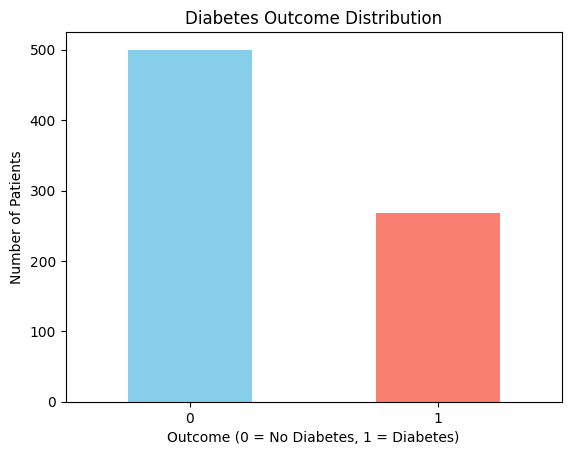

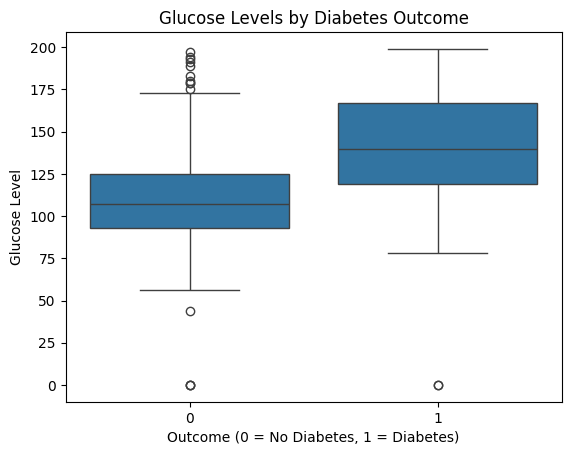

In [4]:

# Graph 1: Diabetes and non-diabetes cases
df["Outcome"].value_counts().sort_index().plot(
    kind="bar", color=["skyblue", "salmon"]
)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()

# Graph 2: Glucose levels by diabetes outcome
sns.boxplot(data=df, x="Outcome", y="Glucose")
plt.title("Glucose Levels by Diabetes Outcome")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Glucose Level")
plt.show()


In [5]:

# Make a copy of the dataset
df_clean = df.copy()

# Zero is not a realistic recorded value for these measurements
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

# Replace zero values with missing values
df_clean[zero_columns] = df_clean[zero_columns].replace(0, np.nan)

# Separate input features and target
X = df_clean.drop("Outcome", axis=1)
y = df_clean["Outcome"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])
print("Preprocessing setup completed!")


Training records: 614
Testing records: 154
Preprocessing setup completed!


In [6]:

# Model 1: Support Vector Machine (SVM)
svm_model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    SVC(kernel="linear", random_state=42)
)

# Model 2: Decision Tree
tree_model = make_pipeline(
    SimpleImputer(strategy="median"),
    DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    )
)

# Train both models
svm_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

print("SVM model trained successfully!")
print("Decision Tree model trained successfully!")


SVM model trained successfully!
Decision Tree model trained successfully!


In [7]:

# Make predictions
svm_predictions = svm_model.predict(X_test)
tree_predictions = tree_model.predict(X_test)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, svm_predictions)
tree_accuracy = accuracy_score(y_test, tree_predictions)

print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")
print("Decision Tree Accuracy:", round(tree_accuracy * 100, 2), "%")

print("\nSVM Classification Report:")
print(classification_report(y_test, svm_predictions, zero_division=0))

print("\nDecision Tree Classification Report:")
print(classification_report(y_test, tree_predictions, zero_division=0))


SVM Accuracy: 70.13 %
Decision Tree Accuracy: 78.57 %

SVM Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.59      0.48      0.53        54

    accuracy                           0.70       154
   macro avg       0.67      0.65      0.66       154
weighted avg       0.69      0.70      0.69       154


Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.84       100
           1       0.70      0.69      0.69        54

    accuracy                           0.79       154
   macro avg       0.76      0.76      0.76       154
weighted avg       0.78      0.79      0.79       154



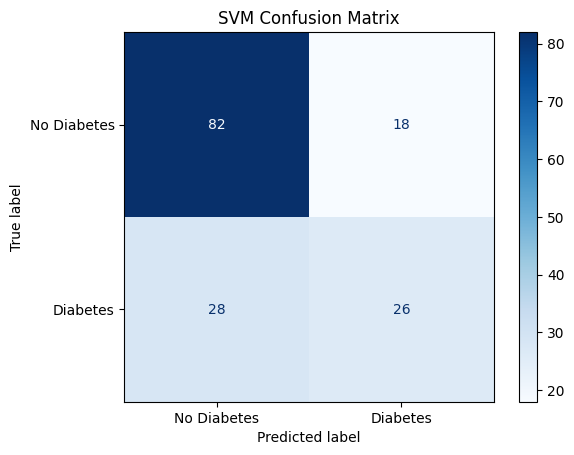

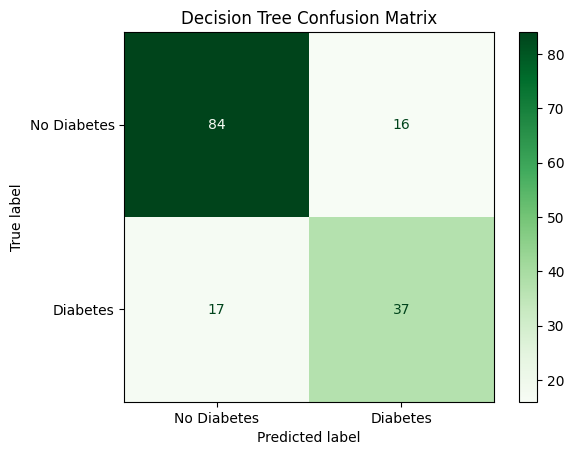

In [8]:

# SVM confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, svm_predictions,
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Blues"
)
plt.title("SVM Confusion Matrix")
plt.show()

# Decision Tree confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, tree_predictions,
    display_labels=["No Diabetes", "Diabetes"],
    cmap="Greens"
)
plt.title("Decision Tree Confusion Matrix")
plt.show()


           Model  Accuracy
0            SVM  0.701299
1  Decision Tree  0.785714


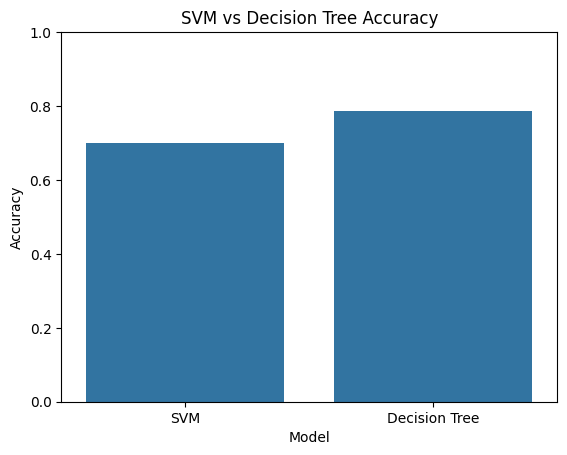

Decision Tree has higher test accuracy.


In [9]:

results = pd.DataFrame({
    "Model": ["SVM", "Decision Tree"],
    "Accuracy": [svm_accuracy, tree_accuracy]
})

print(results)

# Visual comparison
sns.barplot(data=results, x="Model", y="Accuracy")
plt.title("SVM vs Decision Tree Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

# Identify the model with higher test accuracy
if svm_accuracy > tree_accuracy:
    print("SVM has higher test accuracy.")
elif tree_accuracy > svm_accuracy:
    print("Decision Tree has higher test accuracy.")
else:
    print("Both models have equal test accuracy.")


In [10]:

svm_train_accuracy = accuracy_score(
    y_train, svm_model.predict(X_train)
)

tree_train_accuracy = accuracy_score(
    y_train, tree_model.predict(X_train)
)

overfitting_results = pd.DataFrame({
    "Model": ["SVM", "Decision Tree"],
    "Training Accuracy": [svm_train_accuracy, tree_train_accuracy],
    "Testing Accuracy": [svm_accuracy, tree_accuracy]
})

print(overfitting_results)


           Model  Training Accuracy  Testing Accuracy
0            SVM           0.786645          0.701299
1  Decision Tree           0.794788          0.785714


In [11]:

print("FINAL PROJECT CONCLUSION")
print("-------------------------")

print("Dataset: Pima Indians Diabetes Database")
print("Models Used: SVM and Decision Tree")

print("SVM Test Accuracy:", round(svm_accuracy * 100, 2), "%")
print("Decision Tree Test Accuracy:", round(tree_accuracy * 100, 2), "%")

if svm_accuracy > tree_accuracy:
    print("SVM performed better in terms of test accuracy.")
elif tree_accuracy > svm_accuracy:
    print("Decision Tree performed better in terms of test accuracy.")
else:
    print("Both models achieved equal test accuracy.")

print("\nBoth models were trained and evaluated successfully.")
print("This project demonstrates preprocessing, classification,")
print("visualization, evaluation, and model comparison.")

print("\nNote: This project is for educational purposes only.")


FINAL PROJECT CONCLUSION
-------------------------
Dataset: Pima Indians Diabetes Database
Models Used: SVM and Decision Tree
SVM Test Accuracy: 70.13 %
Decision Tree Test Accuracy: 78.57 %
Decision Tree performed better in terms of test accuracy.

Both models were trained and evaluated successfully.
This project demonstrates preprocessing, classification,
visualization, evaluation, and model comparison.

Note: This project is for educational purposes only.
